# Load Dataset from Kaggle

In [ ]:
import json, os
from zipfile import ZipFile

In [ ]:
!pip install -q kaggle

In [ ]:
kaggle_credentials = json.load(open('kaggle.json'))
os.environ['KAGGLE_USERNAME'] = kaggle_credentials['username']
os.environ['KAGGLE_KEY'] = kaggle_credentials['key']

In [ ]:
!kaggle datasets download -d sobhanmoosavi/us-accidents

Dataset URL: https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents
License(s): CC-BY-NC-SA-4.0
 95% 619M/653M [00:02<00:00, 184MB/s]
100% 653M/653M [00:02<00:00, 247MB/s]


In [ ]:
!ls

kaggle.json  sample_data  us-accidents.zip


In [ ]:
with ZipFile('us-accidents.zip', 'r') as zip_ref:
  zip_ref.extractall()

# Importing the Dependencies

In [ ]:
! pip install -q lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

import lime
import lime.lime_tabular

# Data Collection and Analysis

In [ ]:
df = pd.read_csv('US_Accidents_March23.csv', nrows=50000)

df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


In [ ]:
df.shape

(50000, 46)

In [ ]:
df['Severity'].value_counts()

,count
Severity,
2,30061
3,19865
1,58
4,16


In [ ]:
severity_counts = df['Severity'].value_counts().sort_index()

table_data = {'Severity Level': ['Severity 1', 'Severity 2', 'Severity 3', 'Severity 4'],
    'Count': [
        severity_counts.get(1, 0),
        severity_counts.get(2, 0),
        severity_counts.get(3, 0),
        severity_counts.get(4, 0)
    ],
    'Impact Description': [
        'Short Delay',
        'Moderate Delay',
        'High Delay',
        'Very Long Delay'
    ],
    'Action Taken': [
        'Dropped (Low Frequency)',
        'Retained (Mapped to Class 0)',
        'Retained (Mapped to Class 1)',
        'Dropped (Low Frequency)'
    ]
}

summary_table = pd.DataFrame(table_data)

summary_table

,Severity Level,Count,Impact Description,Action Taken
0,Severity 1,58,Short Delay,Dropped (Low Frequency)
1,Severity 2,30061,Moderate Delay,Retained (Mapped to Class 0)
2,Severity 3,19865,Long Delay,Retained (Mapped to Class 1)
3,Severity 4,16,Very Long Delay,Dropped (Low Frequency)


# Data Preprocessing

We filter the dataset to keep only rows where Severity is 2 or 3 then we map them to 0 and 1 respectively.

0 — Mild

1 — Serious


In [ ]:
df = df[df['Severity'].isin([2, 3])].copy()

df['Severity'] = df['Severity'].replace({2: 0, 3: 1})

In [ ]:
df['Severity'].value_counts()

,count
Severity,
0,30061
1,19865


Selecting relevant features

In [ ]:
df['Start_Time'] = pd.to_datetime(df['Start_Time'], errors='coerce')
df['Hour'] = df['Start_Time'].dt.hour
df['Month'] = df['Start_Time'].dt.month
df['Weekday'] = df['Start_Time'].dt.weekday

features = [
    'Severity', 'Start_Lat', 'Start_Lng', 'Distance(mi)',
    'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)',
    'Weather_Condition', 'Sunrise_Sunset', 'Hour', 'Month', 'Weekday',
]

df = df[features].copy()

In [ ]:
df.duplicated().sum()

np.int64(184)

In [ ]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(49742, 14)

In [ ]:
df.isnull().sum()

,0
Severity,0
Start_Lat,0
Start_Lng,0
Distance(mi),0
Temperature(F),449
Humidity(%),632
Pressure(in),299
Visibility(mi),520
Wind_Speed(mph),8362
Weather_Condition,596


Handling missing values

In [ ]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())

df.dropna(subset=['Weather_Condition', 'Sunrise_Sunset'], inplace=True)

df.isnull().sum()

,0
Severity,0
Start_Lat,0
Start_Lng,0
Distance(mi),0
Temperature(F),0
Humidity(%),0
Pressure(in),0
Visibility(mi),0
Wind_Speed(mph),0
Weather_Condition,0


In [ ]:
df.shape

(49146, 14)

In [ ]:
df.head()

,Severity,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Weather_Condition,Sunrise_Sunset,Hour,Month,Weekday
0,1,39.865147,-84.058723,0.01,36.9,91.0,29.68,10.0,8.1,Light Rain,Night,5,2,0
1,0,39.928059,-82.831184,0.01,37.9,100.0,29.65,10.0,8.1,Light Rain,Night,6,2,0
2,0,39.063148,-84.032608,0.01,36.0,100.0,29.67,10.0,3.5,Overcast,Night,6,2,0
3,1,39.747753,-84.205582,0.01,35.1,96.0,29.64,9.0,4.6,Mostly Cloudy,Night,7,2,0
4,0,39.627781,-84.188354,0.01,36.0,89.0,29.65,6.0,3.5,Mostly Cloudy,Day,7,2,0


Separate Independent (X) and Dependent(y) features

In [ ]:
X = df.drop(columns = ['Severity'], axis=1)
y = df['Severity']

In [ ]:
X.head()

,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Weather_Condition,Sunrise_Sunset,Hour,Month,Weekday
0,39.865147,-84.058723,0.01,36.9,91.0,29.68,10.0,8.1,Light Rain,Night,5,2,0
1,39.928059,-82.831184,0.01,37.9,100.0,29.65,10.0,8.1,Light Rain,Night,6,2,0
2,39.063148,-84.032608,0.01,36.0,100.0,29.67,10.0,3.5,Overcast,Night,6,2,0
3,39.747753,-84.205582,0.01,35.1,96.0,29.64,9.0,4.6,Mostly Cloudy,Night,7,2,0
4,39.627781,-84.188354,0.01,36.0,89.0,29.65,6.0,3.5,Mostly Cloudy,Day,7,2,0


In [ ]:
y

,Severity
0,1
1,0
2,0
3,1
4,0
...,...
49995,1
49996,0
49997,0
49998,1


Splitting the data into Training data & Test data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

We use ColumnTransformer to apply different transformers simultaneously. The fit() operation (learning the parameters) is only be performed on the training data
*   OneHotEncoding to categorical features
*   MinMax Scaling to the numerical input features

In [ ]:
cat_cols = ['Weather_Condition', 'Sunrise_Sunset']
num_cols = X.select_dtypes(include=['float64', 'int64']).columns

# defining transformers
ohe = OneHotEncoder(handle_unknown='ignore')
scaler = MinMaxScaler()

# column transformer
tr = [('cat', ohe, cat_cols),
      ('num', scaler, num_cols)]

col_transform = ColumnTransformer(transformers=tr, remainder='passthrough')

X_train_transformed = col_transform.fit_transform(X_train)

X_test_transformed = col_transform.transform(X_test)

# Handling Class Imbalance with SMOTE

Class distribution Before performing SMOTE

Class count before SMOTE:
 Severity
0    23614
1    15702
Name: count, dtype: int64


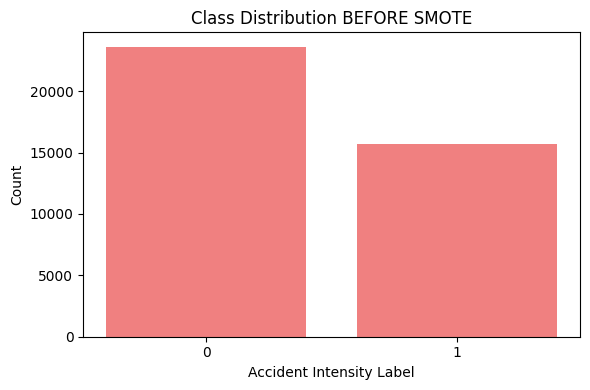

In [ ]:
class_counts_before = pd.Series(y_train).value_counts()
print("Class count before SMOTE:\n", class_counts_before)

plt.figure(figsize=(6, 4))
plt.bar(class_counts_before.index, class_counts_before.values, color='lightcoral')
plt.title('Class Distribution BEFORE SMOTE')
plt.xlabel('Severity Label')
plt.ylabel('Count')
plt.xticks(class_counts_before.index)
plt.tight_layout()
plt.show()

We use SMOTE (Synthetic Minority Over-sampling Technique) to address the class imbalance

In [ ]:
smote = SMOTE(random_state=42)

X_train_res, y_train_res = smote.fit_resample(X_train_transformed, y_train)

Class Distribution After performing SMOTE

Class count after SMOTE:
 Severity
0    23614
1    23614
Name: count, dtype: int64


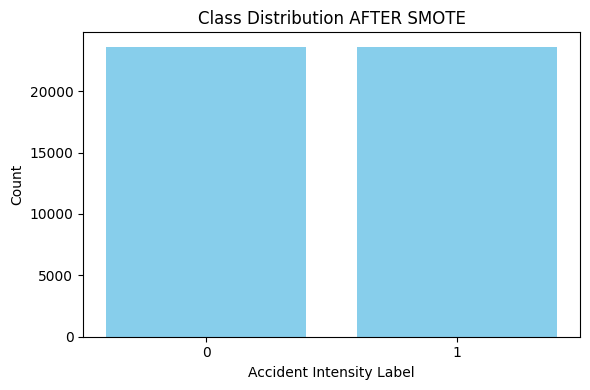

In [ ]:
class_counts_after = pd.Series(y_train_res).value_counts()
print('Class count after SMOTE:\n', class_counts_after)

plt.figure(figsize=(6, 4))
plt.bar(class_counts_after.index, class_counts_after.values, color='skyblue')
plt.title('Class Distribution AFTER SMOTE')
plt.xlabel('Severity Label')
plt.ylabel('Count')
plt.xticks(class_counts_after.index)
plt.tight_layout()
plt.show()

# Model Training

1. Logistic Regression Classifier

In [ ]:
log_reg_model = LogisticRegression(random_state=42, max_iter=1000)

log_reg_model.fit(X_train_res, y_train_res)

LogisticRegression(max_iter=1000, random_state=42)

2. Decision Tree Classifier

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_res, y_train_res)

DecisionTreeClassifier(random_state=42)

3. Random Forest Classifier

In [ ]:
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train_res, y_train_res)

RandomForestClassifier(random_state=42)

4. XGBoost Classifier

In [ ]:
xgb_model = XGBClassifier(random_state=42)

xgb_model.fit(X_train_res, y_train_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

5. KNN Classifier

In [ ]:
knn_model = KNeighborsClassifier()

knn_model.fit(X_train_res, y_train_res)

KNeighborsClassifier()

# Hyper Parameter Optimization

1. **RandomizedSearchCV**

Optimizing DecisionTreeClassifier with *RandomizedSearchCV*

In [ ]:
rscv_dt_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best', 'random'],
    'max_depth': [int(x) for x in np.linspace(10, 1000, 10)] + [None],
    'min_samples_split': [2, 5, 10, 20, 40],
    'min_samples_leaf': [1, 2, 4, 6, 8],
    'max_features': ['sqrt', 'log2', None]
}

dt = DecisionTreeClassifier(random_state=42)

dt_randomcv = RandomizedSearchCV(estimator=dt, param_distributions=rscv_dt_grid, n_iter=100, cv=5, random_state=42,
                                 n_jobs=-1, verbose=2)

dt_randomcv.fit(X_train_res, y_train_res)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'criterion': ['gini', 'entropy',
                                                      'log_loss'],
                                        'max_depth': [10, 120, 230, 340, 450,
                                                      560, 670, 780, 890, 1000,
                                                      None],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 2, 4, 6, 8],
                                        'min_samples_split': [2, 5, 10, 20, 40],
                                        'splitter': ['best', 'random']},
                   random_state=42, verbose=2)

In [ ]:
rscv_dt = dt_randomcv.best_estimator_

rscv_dt.fit(X_train_res, y_train_res)

DecisionTreeClassifier(max_depth=670, min_samples_leaf=2, min_samples_split=40,
                       random_state=42)

Optimizing RandomForestClassifier with *RandomizedSearchCV*

In [ ]:
# Parameter grid definition
rscv_rf_grid = {
    'n_estimators': [int(x) for x in np.linspace(start = 100, stop = 1000, num = 10)],
    'max_depth': [int(x) for x in np.linspace(10, 1000, 10)],
    'min_samples_split': [2, 6, 9, 12, 15],
    'min_samples_leaf': [1, 2, 4, 6, 8],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['entropy','gini']
}

rf = RandomForestClassifier(random_state=42)
rf_randomcv = RandomizedSearchCV(estimator=rf, param_distributions=rscv_rf_grid, n_iter=2, cv=5,
                       random_state=42, n_jobs=-1, verbose=2)

rf_randomcv.fit(X_train_res, y_train_res)

Fitting 5 folds for each of 2 candidates, totalling 10 fits


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=2, n_jobs=-1,
                   param_distributions={'criterion': ['entropy', 'gini'],
                                        'max_depth': [10, 120, 230, 340, 450,
                                                      560, 670, 780, 890,
                                                      1000],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4, 6, 8],
                                        'min_samples_split': [2, 6, 9, 12, 15],
                                        'n_estimators': [100, 200, 300, 400,
                                                         500, 600, 700, 800,
                                                         900, 1000]},
                   random_state=42, verbose=2)

In [ ]:
rscv_rf = rf_randomcv.best_estimator_

rscv_rf.fit(X_train_res, y_train_res)

RandomForestClassifier(max_depth=450, max_features='log2', min_samples_split=9,
                       random_state=42)


Optimizing XGBoostClassifier with *RandomizedSearchCV*

In [ ]:
rscv_xgb_grid = {
    'n_estimators': [int(x) for x in np.linspace(start=100, stop=1000, num=10)],
    'max_depth': [int(x) for x in np.linspace(3, 15, num=5)],
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 2, 3, 4, 5],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4]
}

xgb = XGBClassifier(random_state=42)
xgb_randomcv = RandomizedSearchCV(estimator=xgb, param_distributions=rscv_xgb_grid, n_iter=10, cv=5, random_state=42,
                                  n_jobs=-1, verbose=2)

xgb_randomcv.fit(X_train_res, y_train_res)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constrain...
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.6, 0.7, 0.8, 0.9,
                                                             1.0],
                                        'gamma': [0, 0.1, 0.2, 0.3, 0.4],
                                        'learning_rate': [0.01, 0.05, 0.1, 0.2,
                                                          0.3],
                                        'max_depth': [3, 6, 9, 12, 15],
                                        'min_child_weight': [1, 2, 3, 4, 5],
                                        'n_estimators': [100, 200, 300, 400,
                                                         500, 600, 700, 800,
                                                         900, 1000],
                                        'subsample': [0.6, 0.7, 0.8, 0.9, 1.0]},
                   random_state=42, verbose=2)

In [ ]:
rscv_xgb = xgb_randomcv.best_estimator_

rscv_xgb.fit(X_train_res, y_train_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0.2, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=400,
              n_jobs=None, num_parallel_tree=None, ...)

2. **GridSearchCV**

Optimizing DecisionTreeClassifier with *GridSearchCV*

In [ ]:
gscv_dt_grid = {
    'criterion': [dt_randomcv.best_params_['criterion']],
    'splitter': [dt_randomcv.best_params_['splitter']],
    'max_depth': [dt_randomcv.best_params_['max_depth']],
    'min_samples_split': [max(2, dt_randomcv.best_params_['min_samples_split'] - 2),
        dt_randomcv.best_params_['min_samples_split'],
        dt_randomcv.best_params_['min_samples_split'] + 2],
    'min_samples_leaf': [max(1, dt_randomcv.best_params_['min_samples_leaf'] - 1),
        dt_randomcv.best_params_['min_samples_leaf'],
        dt_randomcv.best_params_['min_samples_leaf'] + 1],
    'max_features': [dt_randomcv.best_params_['max_features']],
}

dt_gridcv = GridSearchCV(estimator=DecisionTreeClassifier(random_state=42), param_grid=gscv_dt_grid, cv=5,
                         n_jobs=-1, verbose=2)

dt_gridcv.fit(X_train_res, y_train_res)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini'], 'max_depth': [670],
                         'max_features': [None], 'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [38, 40, 42],
                         'splitter': ['best']},
             verbose=2)

In [ ]:
gscv_dt = dt_gridcv.best_estimator_

gscv_dt.fit(X_train_res, y_train_res)

DecisionTreeClassifier(max_depth=670, min_samples_leaf=3, min_samples_split=38,
                       random_state=42)

Optimizing RandomForestClassifier with *GridSearchCV*

In [ ]:
gscv_rf_grid = {
    'n_estimators': [rf_randomcv.best_params_['n_estimators']],
    'max_depth': [rf_randomcv.best_params_['max_depth']],
    'min_samples_split': [rf_randomcv.best_params_['min_samples_split'] - 1,
                          rf_randomcv.best_params_['min_samples_split'],
                          rf_randomcv.best_params_['min_samples_split'] + 1],
    'min_samples_leaf': [rf_randomcv.best_params_['min_samples_leaf']],
    'max_features': [rf_randomcv.best_params_['max_features']],
    'criterion': [rf_randomcv.best_params_['criterion']]
}

rf = RandomForestClassifier(random_state=42)
rf_gridcv = GridSearchCV(estimator=rf, param_grid=gscv_rf_grid, cv=5,
                       n_jobs=-1, verbose=2)

rf_gridcv.fit(X_train_res, y_train_res)

Fitting 5 folds for each of 3 candidates, totalling 15 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini'], 'max_depth': [450],
                         'max_features': ['log2'], 'min_samples_leaf': [1],
                         'min_samples_split': [8, 9, 10],
                         'n_estimators': [100]},
             verbose=2)

In [ ]:
gscv_rf = rf_randomcv.best_estimator_

gscv_rf.fit(X_train_res, y_train_res)

RandomForestClassifier(max_depth=450, max_features='log2', min_samples_split=9,
                       random_state=42)

Optimizing XGBoostClassifier with *GridSearchCV*

In [ ]:
gscv_xgb_grid = {
    'n_estimators': [xgb_randomcv.best_params_['n_estimators']],
    'max_depth': [xgb_randomcv.best_params_['max_depth']],
    'colsample_bytree': [xgb_randomcv.best_params_['colsample_bytree']],
    'learning_rate': [xgb_randomcv.best_params_['learning_rate']],
    'subsample': [xgb_randomcv.best_params_['subsample']],
    'min_child_weight': [xgb_randomcv.best_params_['min_child_weight'],
                         xgb_randomcv.best_params_['min_child_weight'] + 1,
                         xgb_randomcv.best_params_['min_child_weight'] + 2],
    'gamma': [max(0.0, xgb_randomcv.best_params_['gamma'] - 0.1),
              xgb_randomcv.best_params_['gamma'],
              xgb_randomcv.best_params_['gamma'] + 0.1]
}

xgb = XGBClassifier(random_state=42)

xgb_gridcv = GridSearchCV(estimator=xgb, param_grid=gscv_xgb_grid, cv=5, n_jobs=-1, verbose=2)

xgb_gridcv.fit(X_train_res, y_train_res)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=Non...
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.9],
                         'gamma': [0.1, 0.2, 0.30000000000000004],
                         'learning_rate': [0.2], 'max_depth': [6],
                         'min_child_weight': [1, 2, 3], 'n_estimators': [400],
                         'subsample': [0.9]},
             verbose=2)

In [ ]:
gscv_xgb = xgb_gridcv.best_estimator_

gscv_xgb.fit(X_train_res, y_train_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0.1, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=400,
              n_jobs=None, num_parallel_tree=None, ...)

# Model Evaluation

In [ ]:
models = {
    "Logistic Regression Model": log_reg_model,
    "Decision Tree Model": dt_model,
    "Random Forest Model": rf_model,
    "XGBoost Model": xgb_model,
    "K-Nearest Neighbors Model": knn_model,
    "RandomizedSearchCV Decision Tree Model": rscv_dt,
    "RandomizedSearchCV Random Forest Model": rscv_rf,
    "RandomizedSearchCV XGBoost Model": rscv_xgb,
    "GridSearchCV Decision Tree Model": gscv_dt,
    "GridSearchCV Random Forest Model": gscv_rf,
    "GridSearchCV XGBoost Model": gscv_xgb
}

In [ ]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Moderate', 'High'],
                yticklabels=['Moderate', 'High'])
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Classification Report:")
    print(classification_report(y_test, y_pred))

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

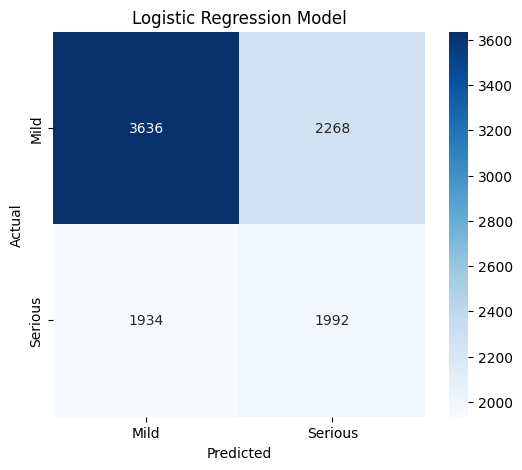

Accuracy: 0.57
Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.62      0.63      5904
           1       0.47      0.51      0.49      3926

    accuracy                           0.57      9830
   macro avg       0.56      0.56      0.56      9830
weighted avg       0.58      0.57      0.58      9830



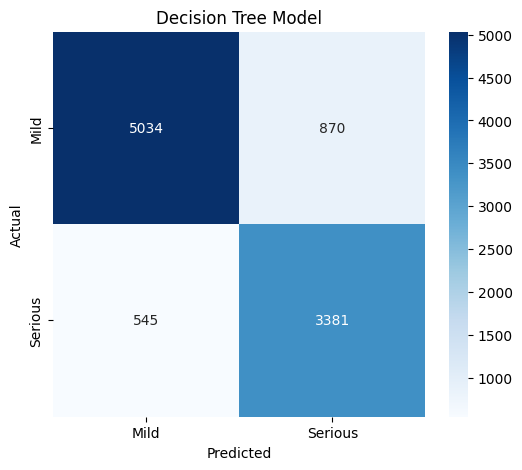

Accuracy: 0.86
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.85      0.88      5904
           1       0.80      0.86      0.83      3926

    accuracy                           0.86      9830
   macro avg       0.85      0.86      0.85      9830
weighted avg       0.86      0.86      0.86      9830



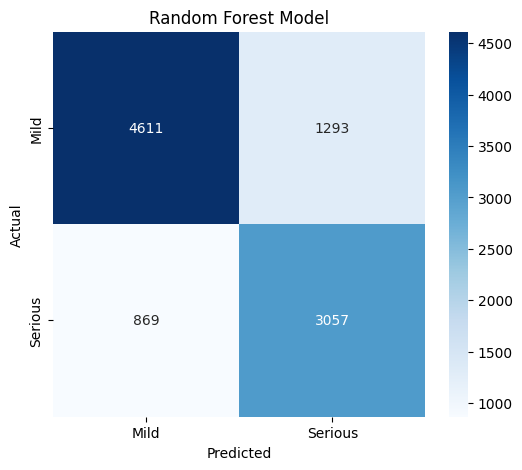

Accuracy: 0.78
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.78      0.81      5904
           1       0.70      0.78      0.74      3926

    accuracy                           0.78      9830
   macro avg       0.77      0.78      0.77      9830
weighted avg       0.79      0.78      0.78      9830



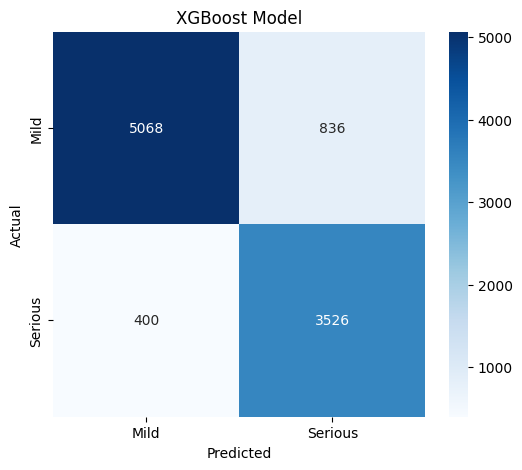

Accuracy: 0.87
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.86      0.89      5904
           1       0.81      0.90      0.85      3926

    accuracy                           0.87      9830
   macro avg       0.87      0.88      0.87      9830
weighted avg       0.88      0.87      0.88      9830



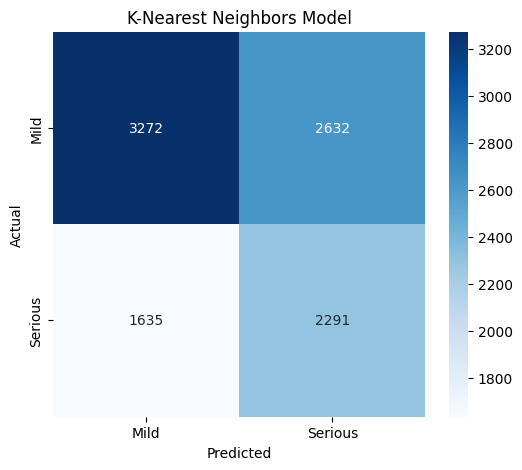

Accuracy: 0.57
Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.55      0.61      5904
           1       0.47      0.58      0.52      3926

    accuracy                           0.57      9830
   macro avg       0.57      0.57      0.56      9830
weighted avg       0.59      0.57      0.57      9830



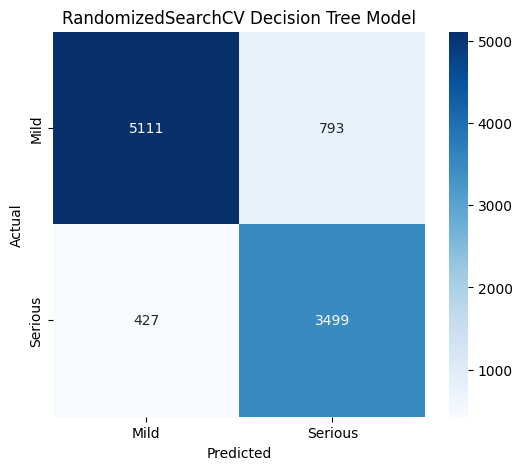

Accuracy: 0.88
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.87      0.89      5904
           1       0.82      0.89      0.85      3926

    accuracy                           0.88      9830
   macro avg       0.87      0.88      0.87      9830
weighted avg       0.88      0.88      0.88      9830



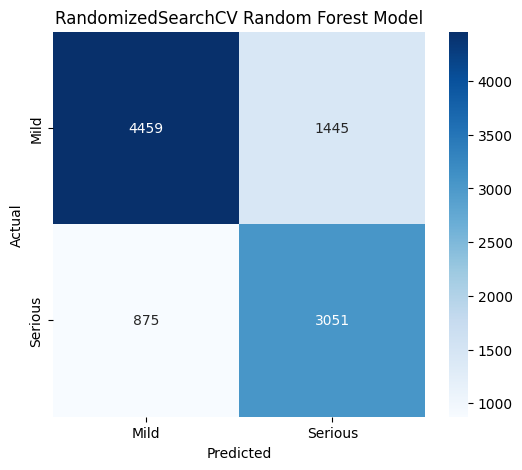

Accuracy: 0.76
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.76      0.79      5904
           1       0.68      0.78      0.72      3926

    accuracy                           0.76      9830
   macro avg       0.76      0.77      0.76      9830
weighted avg       0.77      0.76      0.77      9830



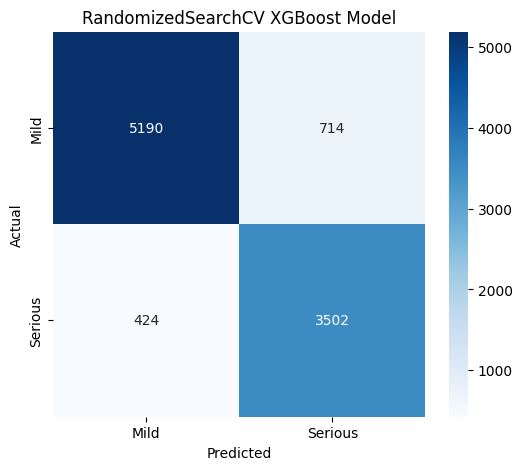

Accuracy: 0.88
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.88      0.90      5904
           1       0.83      0.89      0.86      3926

    accuracy                           0.88      9830
   macro avg       0.88      0.89      0.88      9830
weighted avg       0.89      0.88      0.88      9830



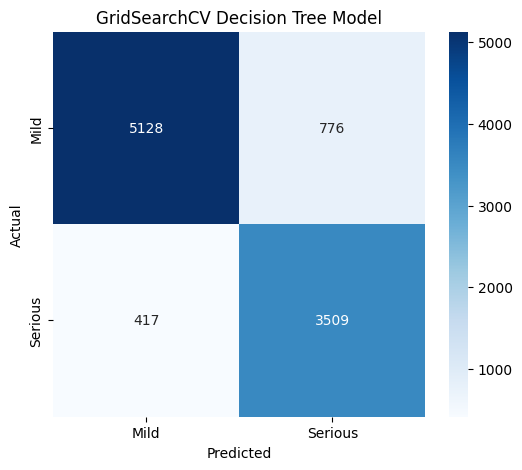

Accuracy: 0.88
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.87      0.90      5904
           1       0.82      0.89      0.85      3926

    accuracy                           0.88      9830
   macro avg       0.87      0.88      0.88      9830
weighted avg       0.88      0.88      0.88      9830



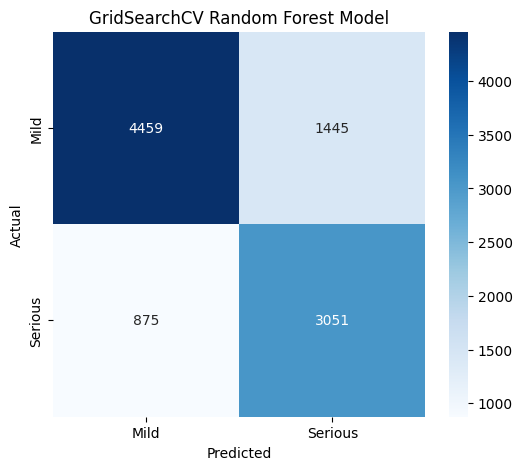

Accuracy: 0.76
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.76      0.79      5904
           1       0.68      0.78      0.72      3926

    accuracy                           0.76      9830
   macro avg       0.76      0.77      0.76      9830
weighted avg       0.77      0.76      0.77      9830



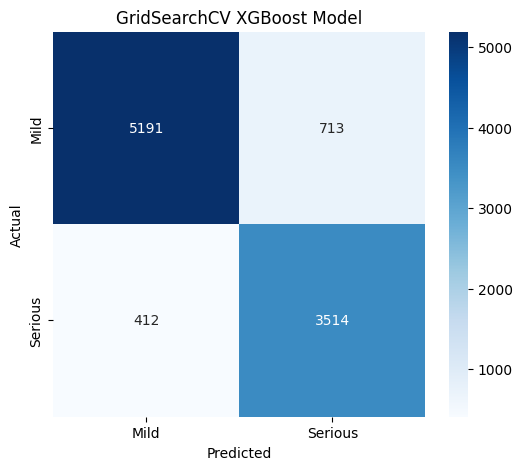

Accuracy: 0.89
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.88      0.90      5904
           1       0.83      0.90      0.86      3926

    accuracy                           0.89      9830
   macro avg       0.88      0.89      0.88      9830
weighted avg       0.89      0.89      0.89      9830



In [ ]:
results = []
for name, model in models.items():
    metrics = evaluate_model(name, model, X_test_transformed, y_test)
    results.append(metrics)

# Comparing the Models

In [ ]:
results_df = pd.DataFrame(results).set_index('Model')
results_df['Rank(by Accuracy)'] = results_df['Accuracy'].rank(ascending=False, method='max').astype(int)

metric_cols = ['Accuracy', 'Precision',	'Recall',	'F1-Score']
results_df[metric_cols] = results_df[metric_cols].round(2)

results_df

,Accuracy,Precision,Recall,F1-Score,Rank(by Accuracy)
Model,,,,,
Logistic Regression Model,0.57,0.58,0.57,0.58,10
Decision Tree Model,0.86,0.86,0.86,0.86,6
Random Forest Model,0.78,0.79,0.78,0.78,7
XGBoost Model,0.87,0.88,0.87,0.88,5
K-Nearest Neighbors Model,0.57,0.59,0.57,0.57,11
RandomizedSearchCV Decision Tree Model,0.88,0.88,0.88,0.88,4
RandomizedSearchCV Random Forest Model,0.76,0.77,0.76,0.77,9
RandomizedSearchCV XGBoost Model,0.88,0.89,0.88,0.88,2
GridSearchCV Decision Tree Model,0.88,0.88,0.88,0.88,3


# Explainable AI

In [ ]:
feature_names = list(col_transform.get_feature_names_out())

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data = X_train_transformed,
    feature_names = feature_names,
    class_names = ['Moderate', 'High'],
    mode = 'classification',
    random_state = 42
)

def predict_fn_xgb(x):
    return gscv_xgb.predict_proba(x)

i = 5
explanation = explainer.explain_instance(
    data_row = X_test_transformed[i],
    predict_fn = predict_fn_xgb,
    num_features = 10
)

explanation.show_in_notebook(show_table=True)